# Student Performance Prediction

# 1. Import Libraries

In [3]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

# 2. Load Dataset

In [4]:
df=pd.read_csv("Final_Marks_Data.csv")
df.head(5)

,Student_ID,Attendance (%),Internal Test 1 (out of 40),Internal Test 2 (out of 40),Assignment Score (out of 10),Daily Study Hours,Final Exam Marks (out of 100)
0,S1000,84,30,36,7,3,72
1,S1001,91,24,38,6,3,56
2,S1002,73,29,26,7,3,56
3,S1003,80,36,35,7,3,74
4,S1004,84,31,37,8,3,66


# 3. Data Exploration

In [5]:
df.isnull().sum()

Student_ID                       0
Attendance (%)                   0
Internal Test 1 (out of 40)      0
Internal Test 2 (out of 40)      0
Assignment Score (out of 10)     0
Daily Study Hours                0
Final Exam Marks (out of 100)    0
dtype: int64

# 4. Data Visualization

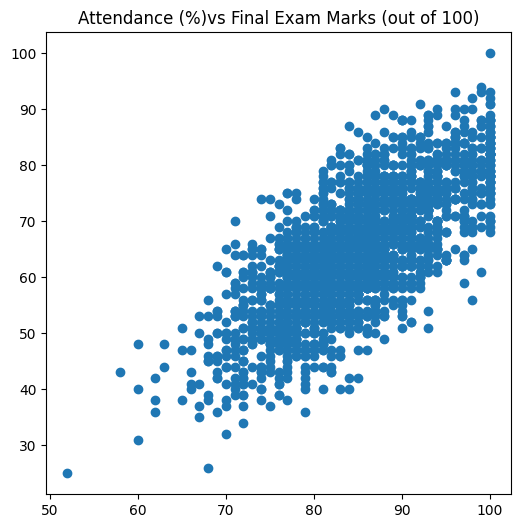

In [6]:
plt.figure(figsize=(6,6))
x=df['Attendance (%)']
y=df['Final Exam Marks (out of 100)']
plt.title("Attendance (%)vs Final Exam Marks (out of 100)")
plt.scatter(x,y)
plt.show()

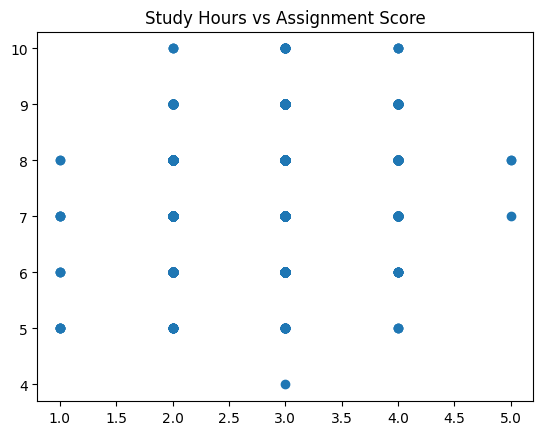

In [7]:
x = df['Daily Study Hours']
y = df['Assignment Score (out of 10)']

plt.scatter(x,y)
plt.title('Study Hours vs Assignment Score')
plt.show()

<Figure size 700x700 with 0 Axes>

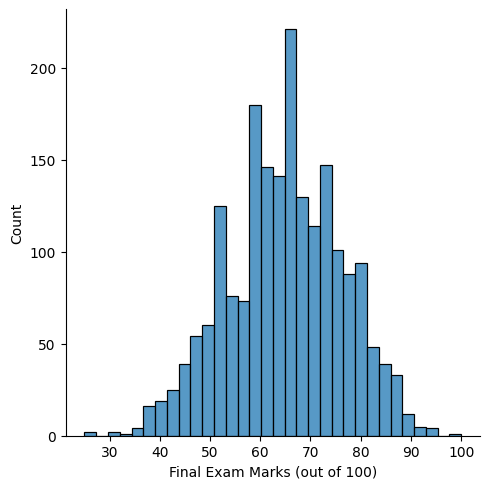

In [8]:
plt.figure(figsize=(7,7))
sns.displot(x=df['Final Exam Marks (out of 100)'])
plt.show()

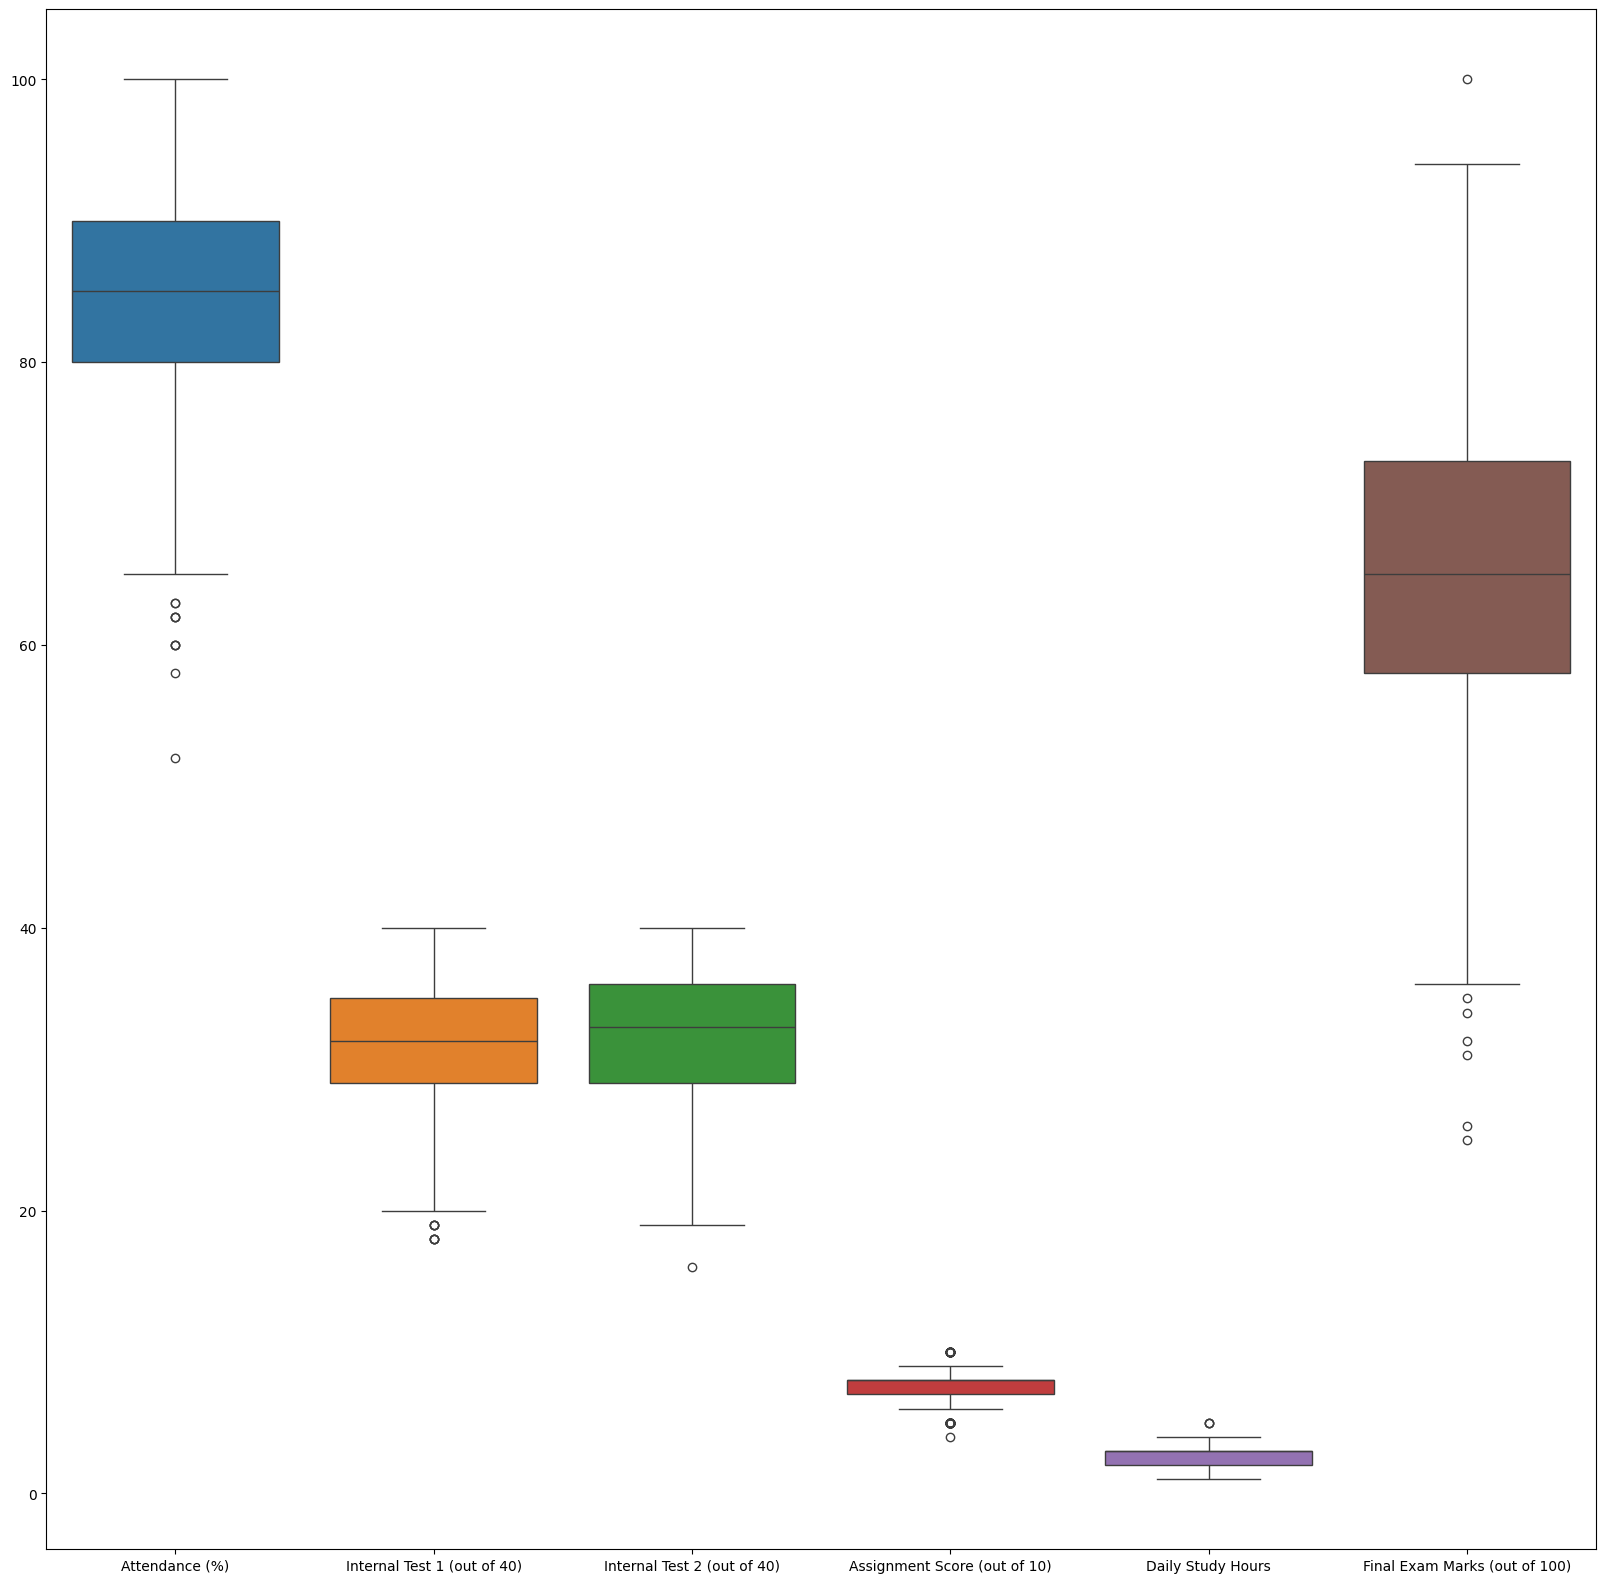

In [9]:
plt.figure(figsize=(20,20))
sns.boxplot(data=df)
plt.show()

In [10]:
# drop student_id
df.drop(columns=['Student_ID'], inplace=True)

# 4.1 Correlation Analysis

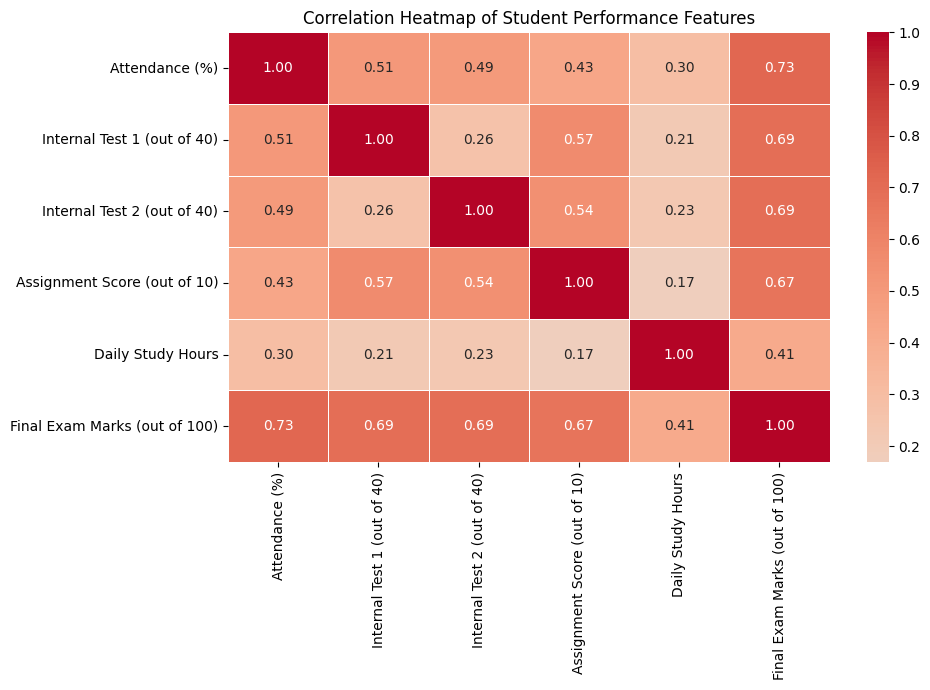

Correlation of features with Final Exam Marks:


,Pearson Correlation
Attendance (%),0.725644
Internal Test 2 (out of 40),0.691049
Internal Test 1 (out of 40),0.689227
Assignment Score (out of 10),0.669400
Daily Study Hours,0.412877


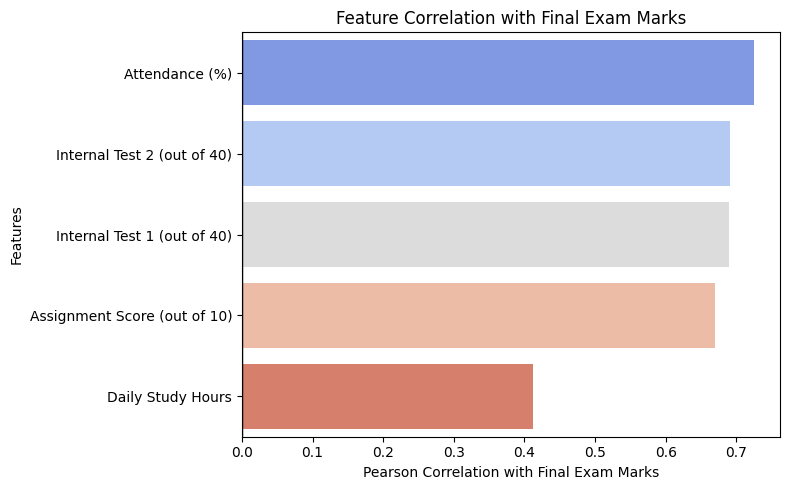

In [11]:
correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(10, 7))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, center=0)
plt.title('Correlation Heatmap of Student Performance Features')
plt.tight_layout()
plt.show()

target_correlation = correlation_matrix['Final Exam Marks (out of 100)'].drop('Final Exam Marks (out of 100)').sort_values(ascending=False)
print('Correlation of features with Final Exam Marks:')
display(target_correlation.to_frame(name='Pearson Correlation'))

plt.figure(figsize=(8, 5))
sns.barplot(x=target_correlation.values, y=target_correlation.index, hue=target_correlation.index, palette='coolwarm', legend=False)
plt.axvline(0, color='black', linewidth=1)
plt.xlabel('Pearson Correlation with Final Exam Marks')
plt.ylabel('Features')
plt.title('Feature Correlation with Final Exam Marks')
plt.tight_layout()
plt.show()

In [12]:
# mathematical information 
df.describe()

,Attendance (%),Internal Test 1 (out of 40),Internal Test 2 (out of 40),Assignment Score (out of 10),Daily Study Hours,Final Exam Marks (out of 100)
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,84.891500,32.115500,32.464500,7.507000,2.823500,64.855000
std,7.758855,4.563504,4.522827,1.021015,0.608714,11.341265
min,52.000000,18.000000,16.000000,4.000000,1.000000,25.000000
25%,80.000000,29.000000,29.000000,7.000000,2.000000,58.000000
50%,85.000000,32.000000,33.000000,8.000000,3.000000,65.000000
75%,90.000000,35.000000,36.000000,8.000000,3.000000,73.000000
max,100.000000,40.000000,40.000000,10.000000,5.000000,100.000000


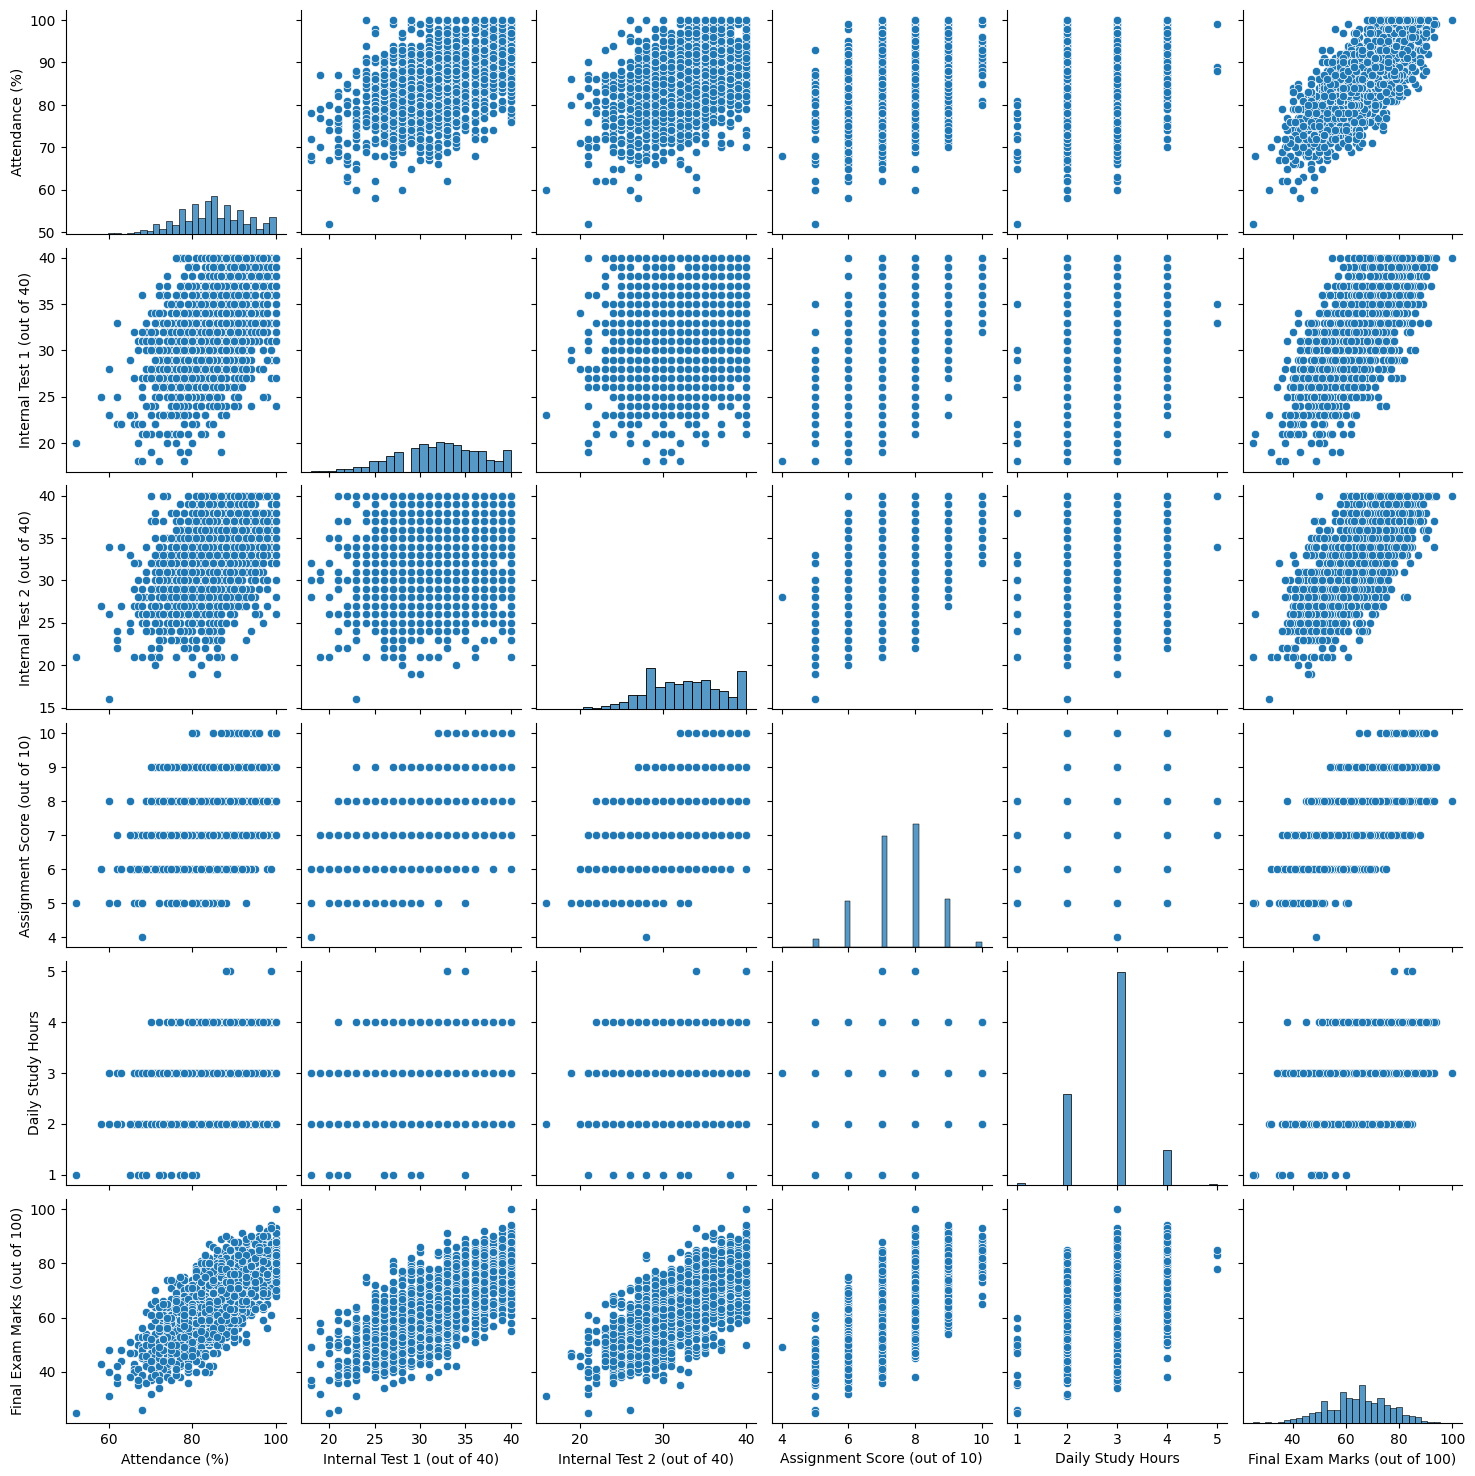

In [13]:
# check linearity
sns.pairplot(data=df)
plt.show()

# 5. Train-Test Split

In [14]:
# differntiate b/w independent and dependent variable
x=df.iloc[:,:-1]
y=df['Final Exam Marks (out of 100)']

In [15]:
# Feature Scaling to improve accuracy
from sklearn.preprocessing import StandardScaler

In [16]:
# apply scikit learn and train_test_split 

from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.20,random_state=42) 

In [17]:
sc = StandardScaler()

x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

# 6. Model Training


In [18]:
# Linear reg
from sklearn.linear_model import LinearRegression
lr=LinearRegression()
lr.fit(x_train,y_train)
lr.score(x_test,y_test)*100 , lr.score(x_train,y_train)*100

(82.9724226438804, 83.87214291420446)

In [19]:
y_pred=lr.predict(x_test)

In [20]:
# use DecisionTreeRegressor
from sklearn.tree import DecisionTreeRegressor
dtr=DecisionTreeRegressor( criterion='squared_error',splitter='best',max_depth=5,random_state=42)
dtr.fit(x_train,y_train)

,"criterion criterion: {""squared_error"", ""friedman_mse"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in the half mean Poisson deviance to find splits... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf

In [21]:
dtr.score(x_test,y_test)*100 , dtr.score(x_train,y_train)*100

(71.58864497388826, 77.41169310926057)

In [22]:
# use KNeighborsRegressor
from sklearn.neighbors import KNeighborsRegressor
knr=KNeighborsRegressor(n_neighbors=15,weights='uniform',leaf_size=4)
knr.fit(x_train,y_train)
knr.score(x_test,y_test)*100,knr.score(x_train,y_train)*100

(80.10940026807111, 83.52288248092124)

In [23]:
# use SVR
from sklearn.svm import SVR
svr=SVR( kernel='rbf',degree=3)
svr.fit(x_train,y_train)
svr.score(x_test,y_test)*100,svr.score(x_train,y_train)*100

(79.13450953310607, 81.14501007545422)

In [24]:
# RandomForest
from sklearn.ensemble import RandomForestRegressor
rf=RandomForestRegressor( n_estimators=100,
    criterion='squared_error',
    max_depth=3,
    min_samples_split=2,
    min_samples_leaf=1,)
rf.fit(x_train,y_train)
rf.score(x_test,y_test)*100,rf.score(x_train,y_train)*100

(71.11424850670227, 73.79658586886735)

# 7. using Hyperparameter for DecisionTreeRegressor

In [25]:
from sklearn.model_selection import GridSearchCV
param_grid = {
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10],
    'criterion': ['squared_error', 'friedman_mse']
}

gd = GridSearchCV(estimator=dtr,param_grid=param_grid,cv=5,scoring='r2')

gd.fit(x_train, y_train)

print("Best Params:", gd.best_params_)
print("Best CV Score:", gd.best_score_ * 100)
print("Test Score:", gd.score(x_test, y_test) * 100)

Best Params: {'criterion': 'squared_error', 'max_depth': 7, 'min_samples_split': 10}
Best CV Score: 73.61040300093545
Test Score: 72.90252917816844


In [26]:
gd.best_params_

{'criterion': 'squared_error', 'max_depth': 7, 'min_samples_split': 10}

In [27]:
# check error 
from sklearn.metrics import mean_absolute_error , mean_squared_error 
import numpy as np 

In [28]:
print("MAE = ",mean_absolute_error(y_test,y_pred))
print("MSE = ",mean_squared_error(y_test,y_pred))
print("RMSE = ",np.sqrt(mean_squared_error(y_test,y_pred)))

MAE =  3.6749513000573044
MSE =  21.325405991113602
RMSE =  4.6179439138120335


# 10. Evaluation Metrics

In [29]:
from sklearn.model_selection import cross_val_score

cv = cross_val_score(svr,x,y, cv=5, scoring='r2')

print("Mean CV Score:", cv.mean()*100)

Mean CV Score: 78.055486158206


In [30]:
from sklearn.ensemble import VotingRegressor
li=[('lr',LinearRegression()),('dtr',DecisionTreeRegressor()),('svr',SVR()),('knr',KNeighborsRegressor())]
vr=VotingRegressor(li)
vr.fit(x_train,y_train)
vr.score(x_test,y_test)*100 , vr.score(x_train,y_train)*100

(80.0655386806423, 91.53855807049793)

In [31]:
prd={'lr':lr.predict(x_test),'dtr':dtr.predict(x_test),'svr':svr.predict(x_test),'knr':knr.predict(x_test),'vr':vr.predict(x_test)}

In [32]:
combined_pred=pd.DataFrame(prd)
combined_pred.head(5)

,lr,dtr,svr,knr,vr
0,64.315781,62.455357,64.956290,63.333333,65.518018
1,55.325154,54.370370,55.150558,55.666667,52.668928
2,65.682564,69.153846,65.682254,64.200000,65.241204
3,46.631086,48.094595,49.298285,50.200000,47.832343
4,41.746401,42.945946,45.706896,44.466667,41.513324


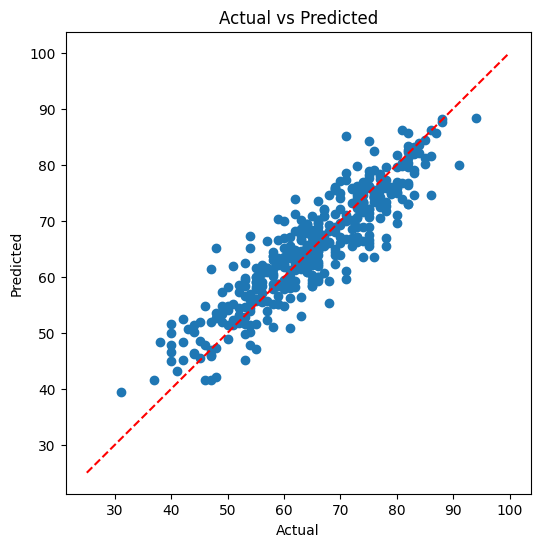

In [33]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, vr.predict(x_test))
plt.plot([y.min(), y.max()],
         [y.min(), y.max()],
         'r--')

plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted")
plt.show()

In [34]:
# Comparision
val=pd.DataFrame({
    "Algo":['lr','dtr','knr','svr','vr','rf'],
    "test_score in %":[82.972,71.588,80.109,79.134,80.284,70.796],
    "train-score in %":[83.872,77.41,83.522,81.145,91.538,73.374]
})

In [35]:
val

,Algo,test_score in %,train-score in %
0,lr,82.972,83.872
1,dtr,71.588,77.410
2,knr,80.109,83.522
3,svr,79.134,81.145
4,vr,80.284,91.538
5,rf,70.796,73.374


In [36]:
# Linear Regression (LR) is the best model because it has:

# The highest test accuracy (82.972%)
# The smallest difference between train and test scores
# Better generalization to unseen data